# QE016: How Much Noise Can a Quantum Code Survive?

**The surface code, its decoders, and the threshold that separates protection from failure.**

Qubits make errors. A quantum error-correcting code spreads one *logical* qubit over many *physical* qubits so that
errors can be detected and undone. The catch is that detection gives only indirect clues (the **syndrome**), and a
**decoder** has to guess which error caused them. A wrong guess can silently flip the logical qubit.

This exercise studies the most important code in practice, the **surface code**, under bit-flip noise:

* **Part A (one exact answer, Euler-style):** the exact failure probability of the best possible decoder for a
  25-qubit surface code, found by checking all 33 million error patterns.
* **Part B1:** best decoder versus a fast practical one (minimum-weight matching), exactly.
* **Part B2:** the **threshold**. Below a critical noise level, bigger codes protect better; above it, they protect
  worse.
* **Part B3:** why the classic decoder of modern telecoms, **belief propagation**, struggles on quantum codes.
* **Part B4:** the information-theoretic limit, and how close the surface code comes to it.
* **Animation:** errors appear, the syndrome lights up, the decoder corrects, and sometimes a logical error slips
  through.

### Words used in this notebook

| term | meaning |
|---|---|
| **physical / logical qubit** | the noisy qubits in hardware / the protected qubit they jointly encode |
| **bit-flip (X) error** | a qubit flips 0 ↔ 1; here each physical qubit flips independently with probability p |
| **stabilizer check** | a measurement of the parity of a few neighbouring qubits; it reveals errors without disturbing the encoded information |
| **syndrome** | the list of checks that came out "odd": the clues an error leaves |
| **decoder** | the algorithm that turns a syndrome into a guess of which qubits to flip back |
| **logical error** | the error plus the correction forms an undetectable chain across the code that flips the logical qubit |
| **distance d** | the length of the shortest such chain; a distance-d surface code has d × d data qubits |
| **degeneracy** | many different errors have the same effect on the logical qubit, so the decoder only needs the right *class* of error, not the exact one |
| **maximum-likelihood (ML) decoder** | the best possible decoder: pick the error class with the highest total probability |
| **minimum-weight perfect matching (MWPM)** | a fast decoder that pairs up lit checks with the shortest possible error chains |
| **belief propagation (BP)** | a message-passing decoder that works superbly for classical codes |
| **threshold** | the noise level below which increasing d makes logical errors rarer |
| **binary entropy h(p)** | the information-theoretic "surprise" of a coin with bias p, $h(p) = -p\log_2 p - (1-p)\log_2(1-p)$ |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `pandas`, `matplotlib` and `pymatching` (`pip install pymatching`). It runs in about
two minutes and writes one GIF animation next to itself.

> **Report version.** This copy shows the text, results, plots and animation only. The full runnable notebook with all code is `QE016_How_Much_Noise_Can_a_Quantum_Code_Survive.ipynb` in the same folder.

## 1. The rotated surface code

Data qubits sit on a $d\times d$ grid. Parity checks sit on the squares between them, in a checkerboard: half of the
squares check for bit-flip errors, the other half (not needed for bit-flip noise) for phase errors. Along the top and
bottom edges there are extra two-qubit checks.

* A single flipped qubit lights up the one or two checks that touch it.
* A chain of flips lights up only its two **ends**.
* A chain running all the way from the left edge to the right edge lights up **nothing**. That is a logical error:
  invisible, and it flips the encoded qubit.

To test whether the leftover error (error + correction) is such a chain, count its flips along the left column: an odd
count means a logical error.

d = 3: 9 data qubits, 4 checks;  a full row of flips lights 0 checks and is a logical error: True
d = 5: 25 data qubits, 12 checks;  a full row of flips lights 0 checks and is a logical error: True
d = 7: 49 data qubits, 24 checks;  a full row of flips lights 0 checks and is a logical error: True


## Part A: the best possible decoder, exactly

Each qubit flips independently with probability $p$. For every syndrome $s$ the ML decoder compares the total
probability of the two error classes (logical flip or not) and picks the larger. It fails with probability

$$P_\text{fail} = 1 - \sum_s \max\big(P(s, \text{no flip}),\; P(s, \text{flip})\big).$$

**Task:** for the distance-5 surface code (25 qubits) at $p = 0.05$, compute the exact ML failure probability and
report

$$A = \lfloor 10^9 \cdot P_\text{fail} \rfloor .$$

*Check value:* the distance-3 code (9 qubits) gives $P_\text{fail} = 0.0368644\ldots$

**Method.** Enumerate all $2^{25} = 33{,}554{,}432$ error patterns in chunks. For each, record its syndrome, its class
and its *weight* (number of flips). The integer counts $N(s, \text{class}, w)$ then give the exact answer for *any* $p$
as a polynomial, which we evaluate with exact fractions.

enumerated 33,554,432 error patterns for d = 5 in 10 s
check, d = 3: P_fail = 0.0368644319
d = 5, p = 0.05: P_fail = 0.024528458130

ANSWER  A = 24528458


So the 25-qubit code turns a 5% physical error rate into a 2.45% logical error rate, even with a perfect decoder. At
this noise level the protection is real but modest.

## Part B1: perfect decoder versus fast decoder

ML decoding is exponentially expensive for large codes. **Minimum-weight perfect matching** instead pairs up the lit
checks (or a lit check with the boundary) along the shortest possible error chains. Here we compare the two
*exactly*: decode each of the $2^{12} = 4096$ syndromes of the $d = 5$ code once with matching, then weigh each
decision by the exact class probabilities.

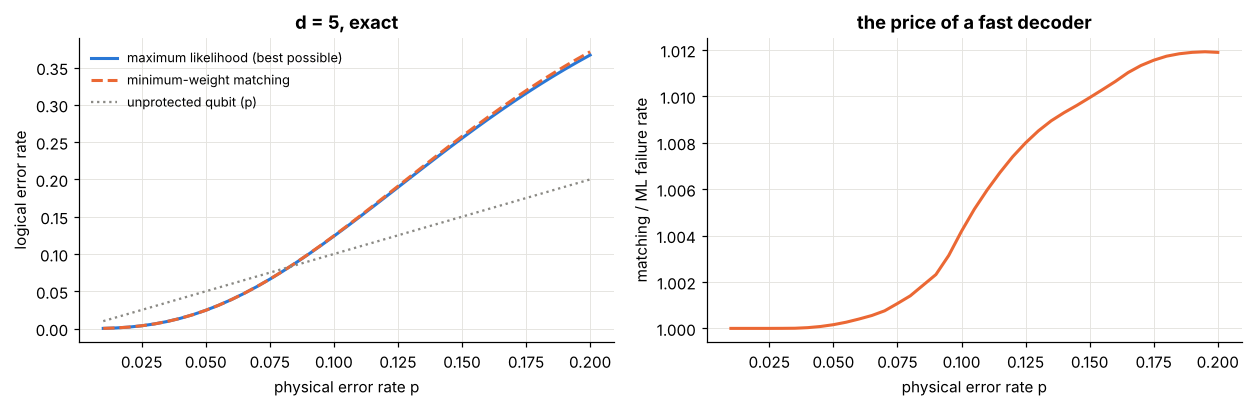

ML beats an unprotected qubit up to p ≈ 0.085;  matching is never more than 1.2% worse than ML for d = 5


For this small code matching is essentially optimal at every noise level: it is never more than about 1% worse than
the perfect decoder. The most likely error is almost always the shortest one. Matching ignores the many longer chains
with the same effect, but that only becomes costly for larger codes near the threshold: for very large surface codes
matching's threshold is about 10.3%, against about 10.9% for the optimal decoder.

## Part B2: the threshold

Now simulate larger codes with matching, using 40,000 random error patterns per point. If $p$ is below the
**threshold**, a larger code suppresses logical errors more strongly; above it, a larger code makes things *worse*,
because there are more ways to build a logical error than the code can correct.

simulated in 15 s


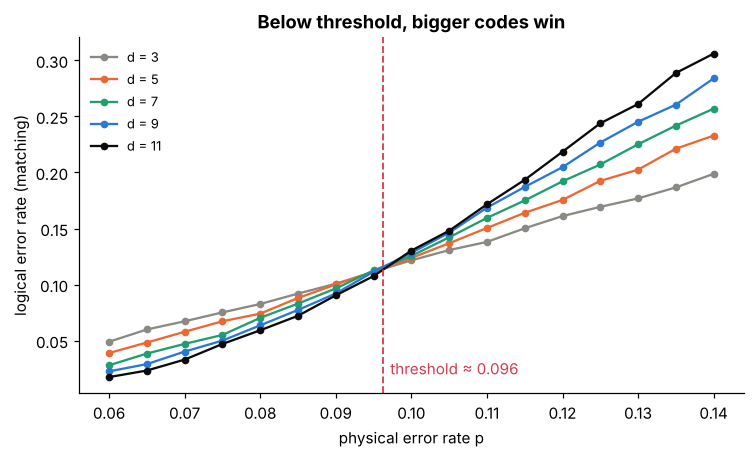

crossings of neighbouring sizes: [np.float64(0.0938), np.float64(0.0965), np.float64(0.0983)]


The curves of neighbouring sizes cross between 9.4% and 9.8%, creeping upwards as the codes grow, towards the
known large-size matching threshold of about 10.3% for this noise model. Below the crossing, every step up in size
cuts the logical error rate; above it, every step up raises it.

## Part B3: why belief propagation struggles

**Belief propagation** passes messages between qubits and checks, each saying "I think this qubit flipped with this
confidence". It decodes classical LDPC codes in Wi-Fi and 5G almost perfectly. On the surface code it often fails, for
two reasons:

* **degeneracy:** many equally likely errors explain the same syndrome, and BP's beliefs split between them instead of
  committing;
* **short loops:** the surface code's checks form many 4-cycles, which violate BP's tree assumption.

Below, standard min-sum BP (up to 50 iterations) and matching decode the same random errors on the $d = 5$ code. BP
"fails" if it never finds a correction matching the syndrome, or finds one that causes a logical error. This
weakness is why quantum codes need new decoders, from belief propagation with post-processing to belief propagation
with *quantum* messages.

computed in 11 s  (BP columns: 300 random errors each, uncertainty about ±3 percentage points)


,BP failure (%),BP did not converge (%),"matching failure, exact (%)","ML failure, exact (%)"
p,,,,
0.02,16.3,16.3,0.2,0.2
0.04,29.0,28.7,1.4,1.4
0.06,47.7,45.7,3.9,3.9
0.08,57.3,55.3,7.7,7.7
0.10,60.3,58.0,12.4,12.4


Most BP failures are failures to converge: the messages keep oscillating between equally good explanations. Matching,
which is built for the surface code's geometry, does an order of magnitude better at low noise.

## Part B4: the information-theoretic limit

Is there a noise level beyond which *no* code can help? For independent bit flips, random CSS codes can carry
quantum information at a positive rate (encoding a fixed fraction of a logical qubit per physical qubit) only while
$1 - 2h(p) > 0$, which requires $p < 11.0\%$. The surface code encodes just one qubit however large it grows (its rate
goes to zero), yet its *optimal* threshold, known from a mapping to a statistical-mechanics model (Dennis, Kitaev,
Landahl and Preskill), is about 10.9%. Matching reaches about 10.3%.

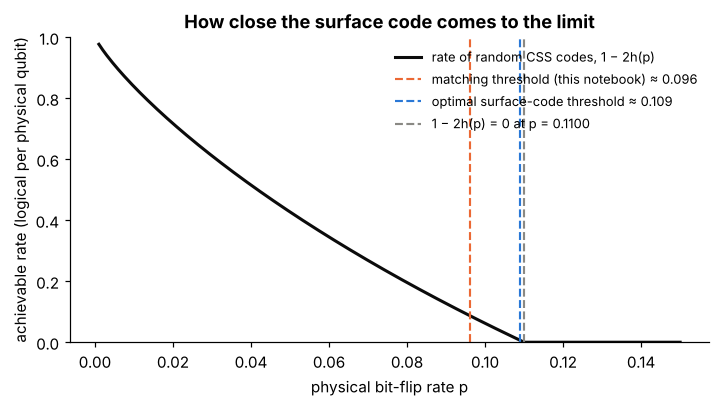

## Animation: one code, many errors

A distance-7 surface code at two noise levels. In each round: red qubits are the errors, orange squares the lit checks
(the syndrome), blue rings the qubits the matching decoder flips back. Then the leftover error is checked. Rounds were
picked to have a typical number of errors and to show both outcomes.

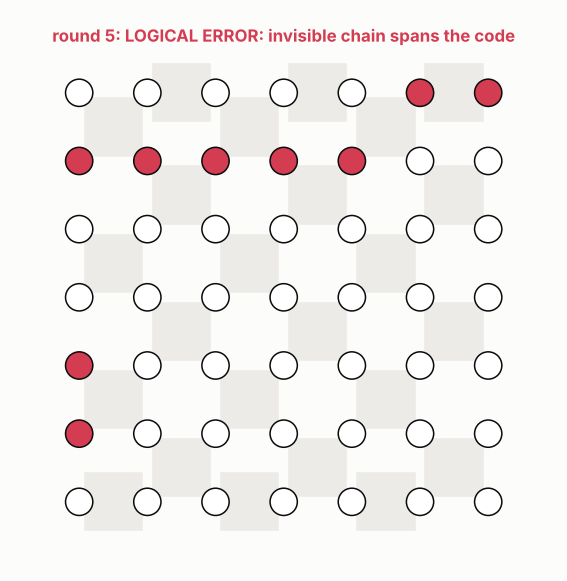

saved qe016_surface_code.gif (17 s)


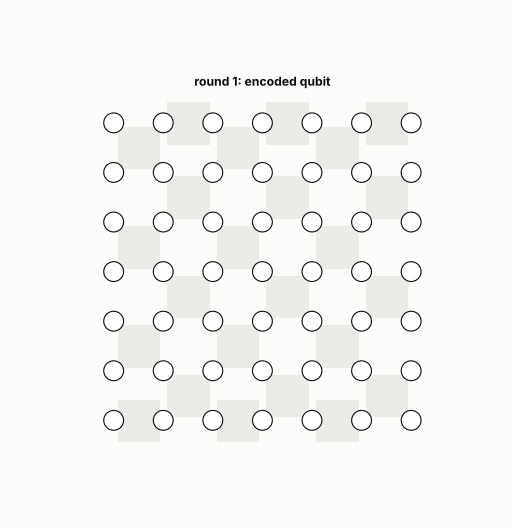

## Conclusions

1. **Exact answer.** The best possible decoder for the 25-qubit surface code at a 5% bit-flip rate fails with
   probability $0.024528458\ldots$, so $A = 24528458$, computed from all 33,554,432 error patterns with exact fractions.
2. **Matching is nearly optimal.** For the 25-qubit code it is within about 1% of the perfect decoder at every noise
   level; the gap only shows for large codes, as a lower threshold (about 10.3% against 10.9%).
3. **The threshold is real.** Below roughly 10% physical error, bigger surface codes protect better; above it, worse.
4. **Belief propagation, a workhorse for classical codes, struggles here**: degeneracy and short loops stop it
   converging. This is a central motivation for new quantum decoders.
5. **The surface code's optimal threshold (~10.9%) sits just below the 11.0% point** where positive-rate random CSS
   codes stop existing.

**Try it yourself:** add phase errors (depolarising noise) and decode both check types, give matching weights from the
true error probabilities, add measurement errors (the threshold drops to a few percent), or try BP followed by a
second-stage decoder (BP+OSD).

### Further reading

* E. Dennis, A. Kitaev, A. Landahl, J. Preskill, *Topological quantum memory*, J. Math. Phys. 43, 4452 (2002).
* A. G. Fowler, M. Mariantoni, J. M. Martinis, A. N. Cleland, *Surface codes: Towards practical large-scale quantum
  computation*, Phys. Rev. A 86, 032324 (2012).
* J. M. Renes, *Quantum Information Theory: Concepts and Methods*, De Gruyter (2022).
* N. Rengaswamy, K. P. Seshadreesan, S. Guha, H. D. Pfister, *Belief propagation with quantum messages for quantum-
  enhanced classical communications*, npj Quantum Information 7, 97 (2021), and J. M. Renes et al., *Quantum
  message-passing algorithm for optimal and efficient decoding*, Quantum 6, 784 (2022).
* O. Higgott, C. Gidney, *Sparse Blossom: correcting a million errors per core second with minimum-weight matching*,
  Quantum 9, 1600 (2025).